# 从价格到持仓：第一套组合回测

这节课的目标是把价格变化转成可以核对的投资账户。你已经理解收益、波动和回撤；这次先不预测市场，也不调参寻找最好收益。

完成后，你应该能：
1. 用 **份额 × 价格 + 现金** 算出账户资产。
2. 解释为什么买入时的 60/40 会逐渐偏离，以及如何恢复比例。
3. 看懂订单、费用、分红与现金记录，区分交易规则和收益表现。
4. 比较月度调仓与买入持有，并知道哪些结论还不能下。

本报告是历史教学模拟，金额单位为美元。数据截止时间会在下一格显示；它不是实时投资建议。

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from market_data import load_snapshot
from portfolio import simulate, reconcile
SNAPSHOT = __import__('os').environ.get('MARKET_LAB_SNAPSHOT', '20261007T234808781424Z')
frames, source_manifest = load_snapshot(SNAPSHOT)
OUT = ROOT / 'reports' / ('02_' + SNAPSHOT)
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'grid.alpha': .2})
print('快照：', SNAPSHOT)
print('日期：', frames['SPY'].index.min().date(), '至', frames['SPY'].index.max().date())
print('价格行数：', {s:len(f) for s,f in frames.items()})
print('保留第一课快照，便于前后比较；本次没有重新下载行情。')

快照： 20261007T234808781424Z
日期： 2010-01-04 至 2026-10-06
价格行数： {'SPY': 4215, 'IEF': 4215, 'GLD': 4215}
保留第一课快照，便于前后比较；本次没有重新下载行情。


## 1. 先约定规则，才有可解释的回测

| 项目 | 本次规则 |
|---|---|
| 初始资金 | 100,000 美元，无后续存取款 |
| 组合 A | 60% SPY（美国大型股票）+ 40% IEF（美国中期国债） |
| 组合 B | SPY / IEF / GLD（黄金）各三分之一 |
| 建仓 | 样本第一天开盘买入，比例在历史模拟开始前指定 |
| 调仓 | 上月最后一个观测日收盘后，决定恢复固定比例；新月第一个观测日开盘成交 |
| 交易成本 | 买和卖分别收取成交额的 5 bps，即 0.05%；是费用和执行摩擦的合并假设 |
| 持仓限制 | 允许零碎份额、不做空、不加杠杆，剩余现金不计利息 |
| 分红 | 除息日开盘交易前，按前日持有份额立即计入现金；不使用 Adj Close 记账 |

**bps（基点）**：1 bps = 0.01%，5 bps = 0.05%。买入 10,000 美元，假设成本就是 5 美元；之后卖出还会再计成本。

重要边界：真实分红通常晚于除息日到账，本次提前计入可用现金是简化；按开盘价算出精确目标数量并在该价全部成交也属于理想化执行，真实订单需在下单时确定数量并考虑滑点。这里采用买卖净额结算，不模拟订单先后、资金结算周期、税费或市场冲击。未做官方交易日历核查，任何资产日期不一致会报错，不自动补值；拆股和资本利得分配暂不支持，遇到会停止。

In [2]:
POLICIES = {'60_40': {'SPY': .6, 'IEF': .4},
            'equal_3': {'SPY': 1/3, 'IEF': 1/3, 'GLD': 1/3}}
NAMES = {'60_40_monthly':'60/40 月度调仓', '60_40_hold':'60/40 买入持有',
         'equal_3_monthly':'三资产 月度调仓', 'equal_3_hold':'三资产 买入持有'}
results = {}
for name, weights in POLICIES.items():
    for monthly in (True, False):
        key = name + ('_monthly' if monthly else '_hold')
        results[key] = simulate(frames, weights, monthly=monthly)
        results[key].daily.to_csv(OUT / (key + '_daily.csv'))
        results[key].trades.to_csv(OUT / (key + '_trades.csv'), index=False)
        results[key].distributions.to_csv(OUT / (key + '_distributions.csv'), index=False)
metrics = pd.DataFrame({k:r.metrics() for k,r in results.items()}).T
metrics.to_csv(OUT / 'metrics.csv')
settings = dict(snapshot=SNAPSHOT, initial_cash=100000, cost_bps=5,
    policies=POLICIES, fractional_shares=True, cash_interest=0,
    distribution_timing='ex-date immediate cash, prior-close entitlement; simplified',
    execution='first observed monthly open, fractional exact sizing; idealized',
    unsupported=['splits','capital gains','shorts','leverage','settlement','tax'],
    source_manifest=source_manifest)
(OUT / 'run_manifest.json').write_text(json.dumps(settings, indent=2), encoding='utf-8')
print('已运行四个版本，并保存每天的持仓、每笔交易和分红。')

已运行四个版本，并保存每天的持仓、每笔交易和分红。


## 2. 第一笔钱是怎样花出去的？

不能先把 100,000 全部买成 ETF，再从零现金里扣手续费。代码先求出**扣除成本后可配置的资产总额**，再按 60/40 分配。

如果全部资金都投入，初次可买入金额 = 100,000 ÷ (1 + 0.0005)，约为 99,950.02 美元，初始费用约 49.98 美元。

交易表里的 `shares` 是交易份额（买入为正、卖出为负），`price` 是模拟成交价，`notional` 是带方向的成交金额，`fee` 是成本。`decision_date` 是决策日期；初始配置预先指定，因此首笔为空。

In [3]:
r = results['60_40_monthly']
display(r.trades.head(4).round(4))
first_date = r.daily.index[0]
first_trades = r.trades[r.trades.date == first_date]
print(f"初次买入金额：${first_trades.notional.sum():,.2f}；费用：${first_trades.fee.sum():,.2f}")
print('当天收盘净值还会受开盘到收盘之间的价格变化影响。')

,date,decision_date,asset,reason,shares,price,notional,fee
0,2010-01-04,NaT,SPY,initial,533.6835,112.37,59970.0150,29.9850
1,2010-01-04,NaT,IEF,initial,450.5298,88.74,39980.0100,19.9900
2,2010-02-01,2010-01-29,SPY,monthly,12.8714,108.15,1392.0426,0.6960
3,2010-02-01,2010-01-29,IEF,monthly,-13.9398,90.26,-1258.2088,0.6291


初次买入金额：$99,950.02；费用：$49.98
当天收盘净值还会受开盘到收盘之间的价格变化影响。


## 3. 权重为什么漂移？

权重 = 某资产当时的市值 ÷ 账户总资产。买入后，份额不变也不意味着权重不变。

例如 60 元股票、40 元债券，股票上涨 10%，债券不变：股票变成 66 元，总资产 106 元，股票权重变成 62.26%。**收益率为 6%，而不是 10%；新的股票权重也不是 66%。**

月度调仓会卖出相对超配的资产、买入相对低配的资产。目标比例在开盘恢复，但当天收盘价格变化后又会偏离。下面同时展示长期权重与第一次月度调仓前的状态。

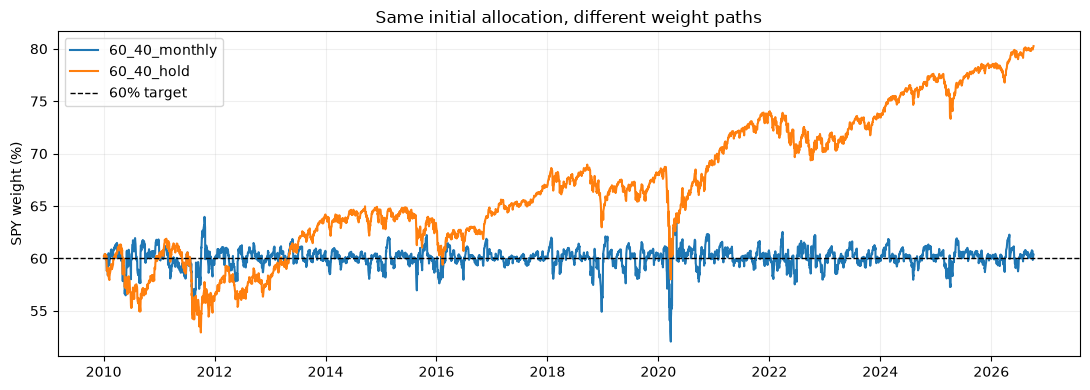

,SPY_pretrade_weight,IEF_pretrade_weight,fees,nav
date,,,,
2010-02-01,0.5859,0.4128,1.3251,98939.6609


,date,decision_date,asset,reason,shares,price,notional,fee
2,2010-02-01,2010-01-29,SPY,monthly,12.8714,108.15,1392.0426,0.6960
3,2010-02-01,2010-01-29,IEF,monthly,-13.9398,90.26,-1258.2088,0.6291


In [4]:
fig, ax = plt.subplots()
for key in ['60_40_monthly', '60_40_hold']:
    ax.plot(results[key].daily.index, results[key].daily.SPY_weight * 100, label=key)
ax.axhline(60, color='black', linestyle='--', linewidth=1, label='60% target')
ax.set(ylabel='SPY weight (%)', title='Same initial allocation, different weight paths')
ax.legend(); fig.tight_layout(); fig.savefig(OUT/'01_weights.png', dpi=150); plt.show()
first_rebalance = r.trades.loc[r.trades.reason == 'monthly', 'date'].iloc[0]
display(r.daily.loc[[first_rebalance], ['SPY_pretrade_weight','IEF_pretrade_weight','fees','nav']].round(4))
display(r.trades[r.trades.date == first_rebalance].round(4))

## 4. 分红不是第二份收益

持有 10 份价格为 100 的 ETF，总值 1,000。假设每份分红 5，除息后价格恰好变成 95：份额市值 950 + 分红现金 50 = 1,000。

不能在调整后价格收益上再加一次分红。本账本使用 Open / Close 和独立分红事件。下面展示真实数据中的第一笔分红及对应现金。

月度版本把积累现金在下次调仓时投入；买入持有版本始终不交易、分红留现金。因此两者差异包含**权重恢复和分红再次投入**，不是纯粹的择时效果，也不等同于第一课“分红再投资近似”的调整后价格曲线。

In [5]:
display(r.distributions.head(4).round(4))
event_date = r.distributions.date.iloc[0]
pos = r.daily.index.get_loc(event_date)
display(r.daily.iloc[max(0,pos-1):pos+2][['nav','cash','distribution','fees']].round(2))
print('累计分红是已经进入组合的钱，不能再次加到最终净值上。')

,date,asset,eligible_shares,per_share,amount
0,2010-02-01,IEF,450.5298,0.300,135.1589
1,2010-03-01,IEF,436.5899,0.244,106.5279
2,2010-03-19,SPY,541.8369,0.480,260.0817
3,2010-04-01,IEF,443.5532,0.255,113.1061


,nav,cash,distribution,fees
date,,,,
2010-01-29,98175.32,0.0,0.00,0.00
2010-02-01,98939.66,0.0,135.16,1.33
2010-02-02,99726.60,0.0,0.00,0.00


累计分红是已经进入组合的钱，不能再次加到最终净值上。


## 5. 历史结果：比较路径，也比较成本

年化复合收益描述起终点的等效增长，年化波动描述每日账户收益的波动，最大回撤描述从历史最高资产值跌下来的最深幅度。初始本金纳入收益和回撤基准，因此建仓成本不会被隐藏。

本次从首日开盘建仓、每天收盘估值；首日收益包含开盘到收盘及建仓费用。年化使用首尾日期之间的实际年数，波动率用每日收益标准差 × √252。费用合计是名义支出，不等于它对最终资产的全部影响（还存在复利和持仓路径差异）。

,期末资产($),累计收益,年化收益,年化波动,最大回撤,累计费用($),交易天数,期末现金($)
60/40 月度调仓,471813.916920,3.718139,0.097029,0.097707,-0.211969,469.348913,202,0.000000
60/40 买入持有,518072.822750,4.180728,0.103171,0.108503,-0.219155,49.975012,1,62129.623565
三资产 月度调仓,396420.125998,2.964201,0.085687,0.085292,-0.170088,517.662429,202,0.000000
三资产 买入持有,419794.700764,3.197947,0.089406,0.091521,-0.178685,49.975012,1,39367.286439


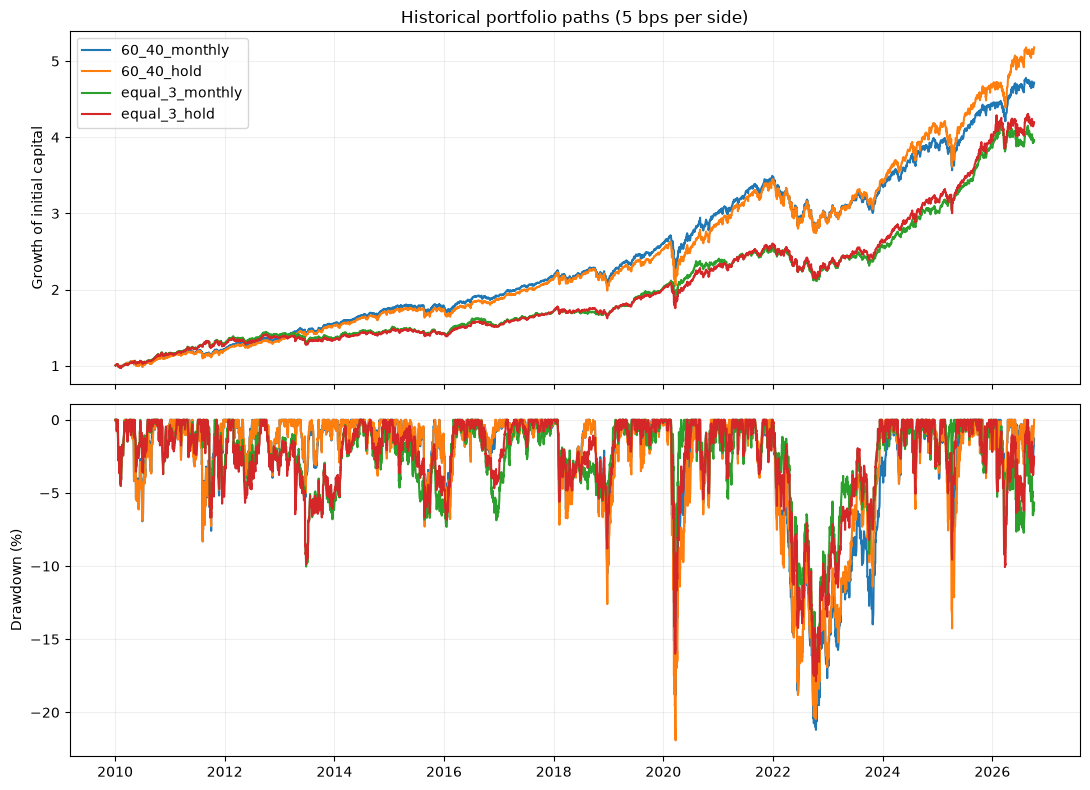

**60/40 月度调仓 vs 买入持有**：月度版本期末资产相差 **$-46,258.91**；年化收益相差 **-0.61 个百分点**。这描述本段历史，不证明调仓永远更好或更差。

**三资产 月度调仓 vs 买入持有**：月度版本期末资产相差 **$-23,374.57**；年化收益相差 **-0.37 个百分点**。这描述本段历史，不证明调仓永远更好或更差。

In [6]:
cols = {'final_nav':'期末资产($)', 'total_return':'累计收益', 'cagr':'年化收益',
        'annual_volatility':'年化波动', 'max_drawdown':'最大回撤',
        'fees_paid':'累计费用($)', 'trade_days':'交易天数', 'ending_cash':'期末现金($)'}
table = metrics[list(cols)].rename(index=NAMES, columns=cols)
display(table.style.format({c: '{:.2%}' for c in ['累计收益','年化收益','年化波动','最大回撤']})
        .format({c:'{:,.2f}' for c in ['期末资产($)','累计费用($)','期末现金($)']})
        .format({'交易天数':'{:.0f}'}))
fig, axes = plt.subplots(2,1,figsize=(11,8),sharex=True)
for key, result in results.items():
    nav = result.daily.nav
    axes[0].plot(nav.index, nav/100000, label=key)
    peak = np.maximum.accumulate(np.r_[100000,nav.to_numpy()])[1:]
    axes[1].plot(nav.index, 100*(nav/peak-1), label=key)
axes[0].set(ylabel='Growth of initial capital',title='Historical portfolio paths (5 bps per side)')
axes[0].legend(); axes[1].set(ylabel='Drawdown (%)')
fig.tight_layout(); fig.savefig(OUT/'02_nav_drawdown.png',dpi=150); plt.show()
for base in POLICIES:
    m, h = metrics.loc[base+'_monthly'], metrics.loc[base+'_hold']
    display(Markdown(f"**{NAMES[base+'_monthly']} vs 买入持有**：月度版本期末资产相差 **${m.final_nav-h.final_nav:,.2f}**；年化收益相差 **{100*(m.cagr-h.cagr):+.2f} 个百分点**。这描述本段历史，不证明调仓永远更好或更差。"))

## 6. 不只看一个成本数字

5 bps 是研究假设，不是查询到的券商报价。我们让其他条件保持不变，把单边成本改为 0 / 5 / 10 bps。

“零成本版本期末资产 − 有成本版本期末资产”包含费用本身及后续复利和交易路径差异。以后实际接入时，还需用成交记录校准这些假设。

In [7]:
sensitivity = []
for name, weights in POLICIES.items():
    for bps in (0,5,10):
        result = results[name+'_monthly'] if bps == 5 else simulate(frames, weights, cost_bps=bps)
        reconcile(result)
        stats = result.metrics()
        sensitivity.append(dict(portfolio=name,cost_bps=bps,final_nav=stats.final_nav,
                                cagr=stats.cagr,fees_paid=stats.fees_paid))
sensitivity = pd.DataFrame(sensitivity)
sensitivity.to_csv(OUT/'cost_sensitivity.csv',index=False)
display(sensitivity.style.format({'final_nav':'{:,.2f}','cagr':'{:.2%}','fees_paid':'{:,.2f}'}))

,portfolio,cost_bps,final_nav,cagr,fees_paid
0,60_40,0,"472,900.15",9.72%,0.00
1,60_40,5,"471,813.92",9.70%,469.35
2,60_40,10,"470,730.25",9.69%,937.33
3,equal_3,0,"397,545.74",8.59%,0.00
4,equal_3,5,"396,420.13",8.57%,517.66
5,equal_3,10,"395,297.83",8.55%,"1,033.45"


## 7. 对账：证明净值确实来自持仓和现金

独立从事件表重建：

- 现金 = 初始资金 + 累计分红 − 累计买入金额 + 累计卖出金额 − 累计成本。
- 每只 ETF 的份额 = 累计买入份额 − 累计卖出份额。
- 总资产 = 所有持仓的收盘市值 + 现金。

另外用人工可算的测试验证：除息不会凭空创造收益、除息日新买入者不得到当天分红、月末决策次月交易、未来价格不改变此前交易。对账通过只能证明这些内部恒等式和规则成立，不能证明外部数据完全准确或策略有盈利能力。

In [8]:
checks = pd.DataFrame({k:reconcile(v) for k,v in results.items()}).T.fillna(0)
checks.to_csv(OUT/'reconciliation.csv')
display(checks)
assert checks.to_numpy().max() < 1e-6
print('四个组合的现金、份额和净值重建通过；差异仅允许浮点误差。')

,cash_error,SPY_shares_error,IEF_shares_error,nav_error,GLD_shares_error
60_40_monthly,4.671165e-09,0.0,0.0,5.820766e-11,0.0
60_40_hold,6.002665e-11,0.0,0.0,5.820766e-11,0.0
equal_3_monthly,2.648449e-09,0.0,0.0,1.455192e-11,0.0
equal_3_hold,1.309672e-10,0.0,0.0,5.820766e-11,0.0


四个组合的现金、份额和净值重建通过；差异仅允许浮点误差。


## 8. 学习练习与下一步

先自己算：60 元股票、40 元债券，股票上涨 10%、债券不变，无成本时要恢复 60/40，应卖多少股票、买多少债券？

提示：先算总资产，再乘目标权重，不要直接把股票盈利的 6 元全部卖掉。下面一格是参考答案。

这一课实际完成的是**可追溯的固定配置基准**。暂时没有 alpha 信号、预测模型或真实订单。

下一课先解释组合风险贡献，再复刻简单反波动率配置；与本课共用数据和评价标准。之后收益信号、风险模型和组合决策可以逐步独立扩展。当前 `simulate` 仅实现固定权重规则，没有伪装成通用交易框架。

限制回顾：分红到账简化、零碎份额、开盘精确成交、现金零利息、无税费与结算、单一数据源且可能事后修订、仅日频估值（看不到日内最深回撤）、历史区间已被观察。本课结果不构成实盘收益承诺。

In [9]:
stock, bond = 60*1.10, 40
total = stock + bond
print(f'总资产 {total:.2f}；新股票权重 {stock/total:.2%}')
print(f'目标股票 {total*.6:.2f}、债券 {total*.4:.2f}')
print(f'卖出股票 {stock-total*.6:.2f}，买入债券 {total*.4-bond:.2f}')
print('如果再考虑成本，需要先扣除费用，目标金额也会略变。')

总资产 106.00；新股票权重 62.26%
目标股票 63.60、债券 42.40
卖出股票 2.40，买入债券 2.40
如果再考虑成本，需要先扣除费用，目标金额也会略变。
